# The Perceptron: Theory, Biological Connection, and Geometric Intuition

### 1. What is a Perceptron?
Proposed by Frank Rosenblatt in 1958, the **Perceptron** is the simplest form of an artificial neural network (ANN) used for binary classification. It is a linear classifier that makes its predictions by estimating a linear decision boundary.

#### Mathematical Formulation
Given an input vector $\mathbf{x} = [x_1, x_2, \dots, x_n]^T$, the perceptron calculates a weighted sum of the inputs, adds a bias ($b$), and applies a step function (often the Heaviside step function):

$$z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^T \mathbf{x} + b$$

$$\hat{y} = f(z) = \begin{cases} 1 & \text{if } z \ge 0 \\ 0 & \text{if } z < 0 \end{cases}$$

Where:
- $\mathbf{x}$ represents the input features.
- $\mathbf{w}$ represents the weight vector determining the importance of each input.
- $b$ is the bias term, shifting the decision boundary away from the origin.
- $f(z)$ is the activation function (step function).
- $\hat{y}$ is the predicted binary class output.

---

### 2. Perceptron vs. Biological Neuron
The artificial Perceptron was directly inspired by the biological structure of a human brain neuron, though it is a highly simplified mathematical abstraction.

| Feature | Biological Neuron | Artificial Perceptron |
| :--- | :--- | :--- |
| **Input Receivers** | **Dendrites**: Receive chemical signals (neurotransmitters) from other neurons. | **Input Features ($x_i$)**: Numerical values representing features of the data point. |
| **Signal Strength** | **Synapses**: Strengthen or weaken the incoming signals. | **Weights ($w_i$)**: Learnable parameters scale the input features. |
| **Processing Unit** | **Soma (Cell Body)**: Accumulates electrical potential. | **Summation Node ($\sum$)**: Computes the weighted sum of inputs plus bias ($z = \mathbf{w}^T\mathbf{x} + b$). |
| **Activation Threshold**| **Action Potential**: Fires an electrical impulse if potential crosses a threshold. | **Activation Function ($f$)**: Outputs `1` or `0` based on whether the sum crosses the threshold (normally 0). |
| **Signal Transmitter** | **Axon**: Transmits the fired signal to other downstream dendrites. | **Output ($\hat{y}$)**: The final binary prediction. |

---

### 3. Geometric Intuition of a Perceptron
Geometrically, a perceptron splits the feature space into two halves using a **decision boundary** (hyperplane).

* **In 2D Space ($n=2$):** The boundary is a **straight line**:
  $$w_1 x_1 + w_2 x_2 + b = 0$$
* **In 3D Space ($n=3$):** The boundary is a **2D flat plane**:
  $$w_1 x_1 + w_2 x_2 + w_3 x_3 + b = 0$$
* **In Higher Dimensions ($n > 3$):** The boundary is a **hyperplane**:
  $$\mathbf{w}^T\mathbf{x} + b = 0$$

#### How Geometric Classification Works
- The weight vector $\mathbf{w}$ is always **perpendicular (orthogonal)** to the decision boundary hyperplane, pointing toward the positive class.
- For any data point $\mathbf{x}$:
  - If the projection of $\mathbf{x}$ onto the weight vector (plus bias) is positive ($z > 0$), the point lies on one side of the hyperplane and is classified as **Class 1**.
  - If the projection is negative ($z < 0$), it lies on the opposite side and is classified as **Class 0**.
  
#### Linear Separability Limitation
Because the decision boundary of a perceptron is strictly a flat line or hyperplane, it can only successfully converge and separate classes that are **linearly separable** (e.g., AND/OR logic gates). It cannot resolve non-linearly separable problems, such as the XOR logic gate, without adding hidden layers (creating a Multi-Layer Perceptron).

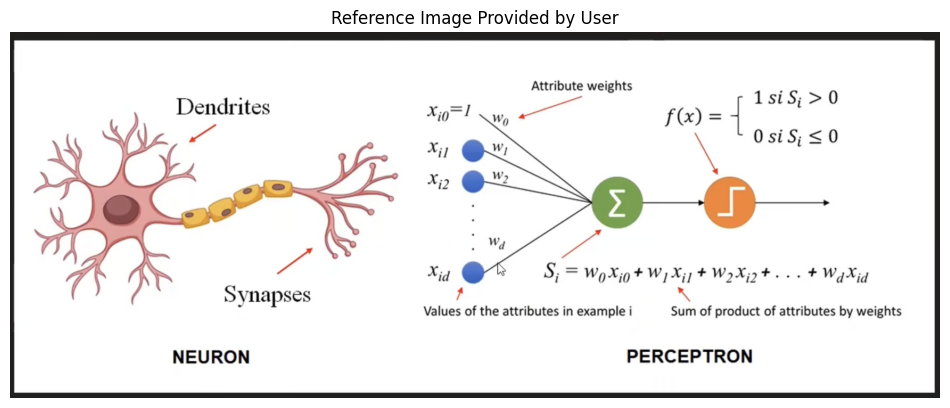

In [4]:
import cv2
import matplotlib.pyplot as plt

# Load and display the user's reference screenshot to inspect its style
img = cv2.imread('/content/Screenshot 2026-10-17 at 10.13.18.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(img_rgb)
plt.axis('off')
plt.title('Reference Image Provided by User')
plt.show()

# Deep Dive: The Perceptron Learning Algorithm & Convergence Theorem

To fully understand how a Perceptron transitions from an arbitrary initial state to the finalized decision boundary shown in the simulation above, we must study its learning algorithm and convergence guarantees.

### 1. The Perceptron Learning Algorithm (PLA)

The Perceptron uses an iterative **error-correction** learning procedure. We define our classes using $y_i \in \{-1, +1\}$ (a common mathematical convention that simplifies the algebra compared to $\{0, 1\}$).

Given training data $\mathcal{D} = \{(\mathbf{x}_1, y_1), (\mathbf{x}_2, y_2), \dots, (\mathbf{x}_N, y_N)\}$:

1. **Initialize** the weight vector $\mathbf{w}(0) = \mathbf{0}$ and bias $b(0) = 0$.
2. **Loop** through each training sample $(\mathbf{x}_i, y_i)$:
3. **Compute** the activation value:
   $$z_i = \mathbf{w}^T \mathbf{x}_i + b$$
4. **Evaluate** the classification condition:
   - If $y_i(\mathbf{w}^T \mathbf{x}_i + b) \le 0$, the point is **misclassified**.
5. **Update** parameters immediately upon detecting a misclassification:
   $$\mathbf{w}(t+1) \leftarrow \mathbf{w}(t) + \eta y_i \mathbf{x}_i$$
   $$b(t+1) \leftarrow b(t) + \eta y_i$$
   *(where $\eta > 0$ is the learning rate)*
6. **Repeat** steps 2-5 until all training samples are classified correctly ($y_i(\mathbf{w}^T \mathbf{x}_i + b) > 0$ for all $i$).

---

### 2. Geometric Mechanics of the Update Rule
Why does the update rule $\mathbf{w} \leftarrow \mathbf{w} + y_i \mathbf{x}_i$ work?

- If a positive instance ($y_i = +1$) is misclassified, then $\mathbf{w}^T \mathbf{x}_i < 0$ (the angle between $\mathbf{w}$ and $\mathbf{x}_i$ is obtuse).
- Adding $\mathbf{x}_i$ to $\mathbf{w}$ yields a new weight vector $\mathbf{w}_{\text{new}} = \mathbf{w} + \mathbf{x}_i$.
- The new dot product becomes:
  $$\mathbf{w}_{\text{new}}^T \mathbf{x}_i = (\mathbf{w} + \mathbf{x}_i)^T \mathbf{x}_i = \mathbf{w}^T \mathbf{x}_i + \|\mathbf{x}_i\|^2$$
- Because $\|\mathbf{x}_i\|^2 > 0$, the value of the dot product is pushed in the positive direction, making it more likely to classify $\mathbf{x}_i$ correctly in future iterations.

---

### 3. Novikoff's Convergence Theorem
One of the most powerful theoretical properties of the Perceptron is that **if the dataset is linearly separable, the algorithm is guaranteed to converge in a finite number of steps.**

#### Theorem Statement
Let the training set $\mathcal{D}$ be linearly separable, meaning there exists a unit weight vector $\mathbf{w}^*$ (with $\|\mathbf{w}^*\| = 1$) and a margin $\gamma > 0$ such that:
$$y_i (\mathbf{w}^{*T} \mathbf{x}_i) \ge \gamma \quad \forall i$$

Let $R = \max_i \|\mathbf{x}_i\|$ be the maximum norm of any input vector in the dataset.

Assuming we start with $\mathbf{w}(0) = \mathbf{0}$, the maximum number of updates $k$ before the algorithm converges is bounded by:

$$k \le \frac{R^2}{\gamma^2}$$

#### Implications
- **No dependence on dimension:** The bound on the number of iterations depends only on the scale of the data ($R$) and how clean the separation is (the margin $\gamma$), not on the dimensionality of the feature space.
- **Unseparable Data:** If the dataset is not linearly separable, the algorithm will cycle infinitely. This led to the development of softer linear algorithms (like Support Vector Machines) and multi-layer structures.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv('placement.csv')
df.head()

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1


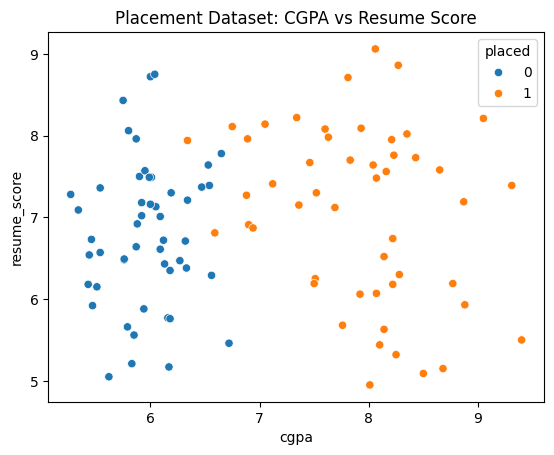

In [10]:
sns.scatterplot(data=df, x='cgpa', y='resume_score', hue='placed')
plt.title('Placement Dataset: CGPA vs Resume Score')
plt.show()

In [13]:
from sklearn.linear_model import Perceptron
p = Perceptron()

In [14]:
x = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [15]:
p.fit(x,y)

Perceptron()

In [17]:
p.coef_ # these are the weights

array([[ 40.26, -36.  ]])

In [18]:
p.intercept_ # this is the bias

array([-25.])

In [19]:
from mlxtend.plotting import plot_decision_regions

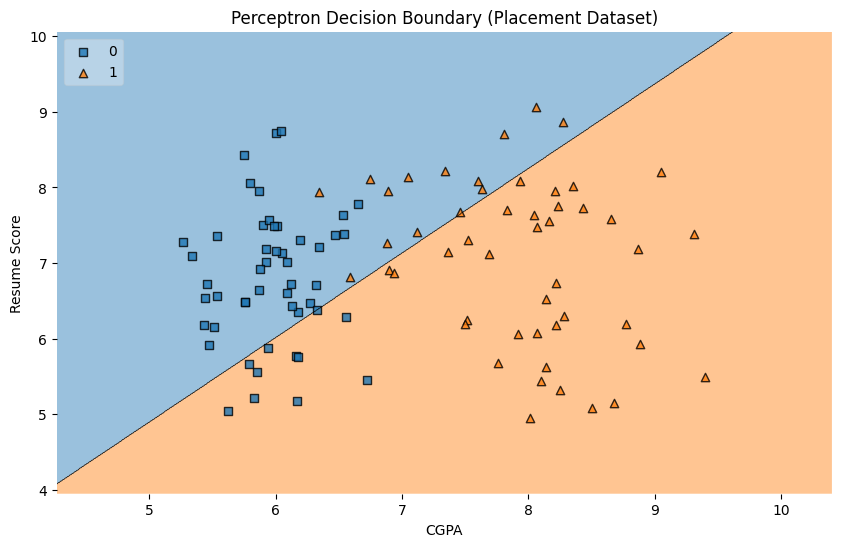

In [24]:
import warnings
plt.figure(figsize=(10, 6))

# Suppress the scikit-learn feature name warning since mlxtend requires raw NumPy arrays
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    plot_decision_regions(x.values, y.values, clf=p, legend=2)

plt.xlabel('CGPA')
plt.ylabel('Resume Score')
plt.title('Perceptron Decision Boundary (Placement Dataset)')
plt.show()